 ## 1.1 Importer les packages

In [1]:
# Importer les packages
import tensorflow as tf
import numpy as np
import pandas as pd
import os
import joblib
from tensorflow.keras.models import Sequential
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, BatchNormalization, Dropout
from tensorflow.keras.applications import VGG16, DenseNet121
from keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

## 1.2 Importer les données


L'ensemble de données **CIFAR10** contient 60 000 images couleur réparties en 10 classes (airplane, automobile, bird, cat,deer, dog, frog, horse, ship, truck), avec 6 000 images dans chaque classe. L'ensemble de données est divisé en 50 000 images d'apprentissage et 10 000 images de test. Les classes s'excluent mutuellement et ne se chevauchent pas.

In [2]:
# importer les données : fichier cifar10.joblib s'il est dans le dossier du notebook, sinon téléchargement par keras
import joblib as jb
if os.path.exists('cifar10.joblib'):
  (train_images, train_labels), (test_images, test_labels) = jb.load('cifar10.joblib')
else:
  (train_images, train_labels), (test_images, test_labels) = cifar10.load_data()

### Paramètres du mode local

Sans GPU, l'entraînement des trois modèles sur CIFAR-10 complet serait très long. Ces paramètres réduisent le calcul :
- `NB_TRAIN` et `NB_TEST` : nombre d'images utilisées (mettre `None` pour utiliser tout le jeu de données) ;
- `MAX_EPOCHS_TUNER` : epochs maximum du tuner (10 sur Colab avec GPU) ;
- `EPOCHS_FINAL` : epochs maximum de l'entraînement final (l'early stopping arrête avant si la loss de validation ne s'améliore plus).

In [3]:
# Paramètres du mode local (mettre NB_TRAIN = None et NB_TEST = None pour tout le jeu de données)
NB_TRAIN = 10000
NB_TEST = 2000
MAX_EPOCHS_TUNER = 5
EPOCHS_FINAL = 20
if NB_TRAIN is not None:
  train_images, train_labels = train_images[:NB_TRAIN], train_labels[:NB_TRAIN]
if NB_TEST is not None:
  test_images, test_labels = test_images[:NB_TEST], test_labels[:NB_TEST]
train_images.shape, test_images.shape

((10000, 32, 32, 3), (2000, 32, 32, 3))

In [4]:
# Normaliser les valeurs de pixel en divisant par 255 (en float32 pour économiser la mémoire)
train_images, test_images = (train_images/255).astype('float32'), (test_images/255).astype('float32')

In [5]:
# Afficher la première image en format matriciel d'index 0
train_images[0]

array([[[0.23137255, 0.24313726, 0.24705882],
        [0.16862746, 0.18039216, 0.1764706 ],
        [0.19607843, 0.1882353 , 0.16862746],
        ...,
        [0.61960787, 0.5176471 , 0.42352942],
        [0.59607846, 0.49019608, 0.4       ],
        [0.5803922 , 0.4862745 , 0.40392157]],

       [[0.0627451 , 0.07843138, 0.07843138],
        [0.        , 0.        , 0.        ],
        [0.07058824, 0.03137255, 0.        ],
        ...,
        [0.48235294, 0.34509805, 0.21568628],
        [0.46666667, 0.3254902 , 0.19607843],
        [0.47843137, 0.34117648, 0.22352941]],

       [[0.09803922, 0.09411765, 0.08235294],
        [0.0627451 , 0.02745098, 0.        ],
        [0.19215687, 0.10588235, 0.03137255],
        ...,
        [0.4627451 , 0.32941177, 0.19607843],
        [0.47058824, 0.32941177, 0.19607843],
        [0.42745098, 0.28627452, 0.16470589]],

       ...,

       [[0.8156863 , 0.6666667 , 0.3764706 ],
        [0.7882353 , 0.6       , 0.13333334],
        [0.7764706 , 0

In [6]:
# Dimension des données train et test
train_images.shape, test_images.shape

((10000, 32, 32, 3), (2000, 32, 32, 3))

Pour vérifier que l'ensemble de données semble correct, affichons les 25 premières images de l'ensemble d'apprentissage et affichons le nom de la classe sous chaque image.

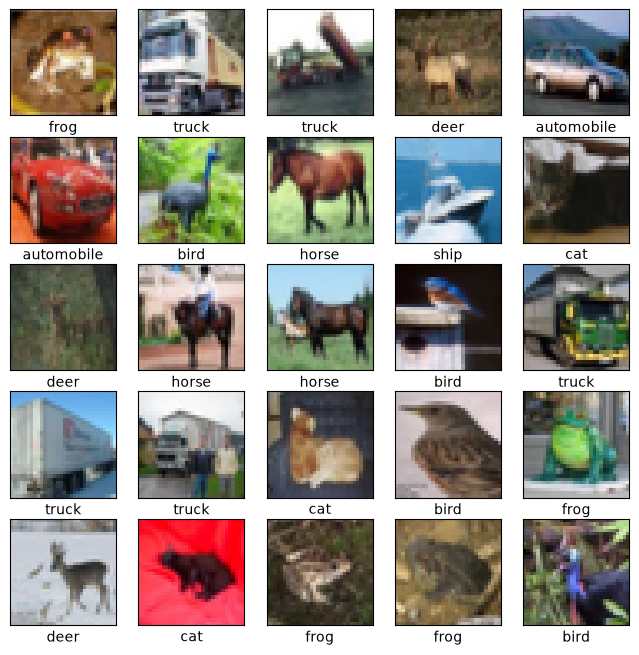

In [7]:
# Noms des classes des images
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# Plotter 25 images des données train
plt.figure(figsize=(8,8))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i][0]])
plt.show()

## Créer les modèles

On compare trois modèles : le **CNN** du cours, **VGG16** et **DenseNet121** (base préentraînée sur `imagenet`, gelée). Pour chacun, on recherche les hyperparamètres optimaux avec Keras Tuner (Hyperband, objectif `val_accuracy`), puis on réentraîne le modèle final avec ces valeurs.

**Taille des images.** Les images CIFAR-10 font 32×32. Avec `include_top=False`, VGG16 et DenseNet121 acceptent une taille d'entrée minimale de 32×32 : aucun redimensionnement n'est nécessaire, on garde donc `input_shape=(32, 32, 3)` (ce qui réduit aussi le temps de calcul sur la T4).

**Alignement tuner / modèle final.** Chaque modèle est défini une seule fois dans une fonction `build_model_...(hp)`. Le modèle final est construit en appelant cette même fonction avec les hyperparamètres optimaux (`best_hps`) : l'architecture cherchée par le tuner et l'architecture finale sont ainsi identiques (y compris `BatchNormalization` pour le CNN).

**Données de validation.** Comme dans le cours, le jeu `test` de CIFAR-10 sert de données de validation (`validation_data`).

### Installer et importer Keras Tuner

In [8]:
# Installer keras tuner (et tensorboard, nécessaire à keras tuner)
%pip install keras-tuner tensorboard

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
# importer le package keras_tuner
import keras_tuner as kt

### Fonctions d'évaluation (courbes, matrice de confusion)

In [10]:
# Importer ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Fonction affichant la matrice de confusion d'un modèle sur les données de validation
def CM_visualisation(model_objet):
    # classe prédite = classe avec la plus grande probabilité
    val_pred = np.argmax(model_objet.predict(test_images, verbose = 0), axis = 1)
    cnf_matr = confusion_matrix(test_labels.ravel(), val_pred, labels = range(10))
    disp = ConfusionMatrixDisplay(confusion_matrix = cnf_matr, display_labels = class_names)
    fig, ax = plt.subplots(figsize = (9, 9))
    disp.plot(ax = ax, xticks_rotation = 45)
    plt.title('Matrice de confusion')
    plt.show()

# Fonction affichant les courbes d'accuracy et de loss (train et validation)
def courbes(history_objet):
    # Evolution de l'accuracy sur les données d'entrainement et de validation suivant les différents epochs
    plt.plot(history_objet.history['accuracy'])
    plt.plot(history_objet.history['val_accuracy'])
    plt.title("Evolution l'accuracy sur train et val data")
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend(['Train', 'Validation'], loc = 'lower right')
    plt.show()
    # Evolution du loss sur les données d'entrainement et de validation suivant les différents epochs
    plt.plot(history_objet.history['loss'])
    plt.plot(history_objet.history['val_loss'])
    plt.title("Evolution de loss sur train et val data")
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend(['Train', 'Validation'], loc = 'upper right')
    plt.show()

# Dictionnaire qui va contenir les modèles finaux et leurs résultats
models = {}
resultats = {}

## Modèle 1 : CNN du cours

### Rechercher les paramètres optimaux

Hyperparamètres recherchés : le nombre de filtres des trois couches convolutives (16, 32, 64 ou 128).

In [11]:
# fonction build_model du CNN
def build_model_cnn(hp):
  model = Sequential() # initialiser l'architecture CNN

  # Choisir le nombre de filtre optimal pour les couches convolutives
  hp_filters1 = hp.Choice('filters1', values = [16, 32, 64, 128])
  hp_filters2 = hp.Choice('filters2', values = [16, 32, 64, 128])
  hp_filters3 = hp.Choice('filters3', values = [16, 32, 64, 128])

  # Couches convolutives avec BatchNormalization et Pooling
  model.add(Conv2D(hp_filters1, (3, 3), activation='relu', padding = 'same', input_shape = (32, 32, 3)))
  model.add(BatchNormalization())
  model.add(MaxPooling2D((2, 2)))
  model.add(Conv2D(hp_filters2, (3, 3), activation='relu', padding = 'same'))
  model.add(BatchNormalization())
  model.add(MaxPooling2D((2, 2)))
  model.add(Conv2D(hp_filters3, (3, 3), activation='relu', padding = 'same'))
  model.add(BatchNormalization())
  model.add(MaxPooling2D((2, 2)))

  # Couches fully connected
  model.add(Flatten()) # Couche flatten
  model.add(Dense(256, activation = 'relu')) # Dense 1
  model.add(Dropout(0.5)) # Dropout 1
  model.add(Dense(128, activation = 'relu')) # Dense 2
  model.add(Dropout(0.5)) # Dropout 2
  model.add(Dense(10, activation = 'softmax')) # Output : 10 classes

  # compiler le modèle
  model.compile(optimizer = 'adam', loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

  return model

In [12]:
# Initialiser le tuner
import keras_tuner as kt
tuner_cnn = kt.Hyperband(build_model_cnn,
                     objective='val_accuracy',   # on optimise l'accuracy sur les données de validation
                     max_epochs=MAX_EPOCHS_TUNER,
                     directory='tuner_dir',
                     project_name='cnn_cifar10',
                     overwrite=True              # repart de zéro (ignore les essais ratés précédents)
                     )

# lancer la recherche avec le tuner
tuner_cnn.search(train_images, train_labels, validation_data = (test_images, test_labels), epochs = MAX_EPOCHS_TUNER, batch_size = 64)

Trial 10 Complete [00h 01m 50s]
val_accuracy: 0.484499990940094

Best val_accuracy So Far: 0.5400000214576721
Total elapsed time: 00h 17m 51s


In [13]:
# Afficher les paramètres optimaux
best_hps_cnn = tuner_cnn.get_best_hyperparameters()[0]
for h_param in [f"filters{i}" for i in range(1,4)]:
  print(h_param, best_hps_cnn.get(h_param))

filters1 32
filters2 32
filters3 32


### Modèle final et entrainement

In [14]:
# Créer l'architecture du modèle avec les hyperparamètres optimaux
cnn_model = build_model_cnn(best_hps_cnn)
# Summary du modèle
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 185,290 (723.79 KB)

 Trainable params: 185,098 (723.04 KB)

 Non-trainable params: 192 (768.00 B)

In [15]:
# Définir le early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=3)
# Entrainer le modèle (la compilation est faite dans build_model_cnn : adam, sparse_categorical_crossentropy, accuracy)
history_cnn = cnn_model.fit(train_images, train_labels, validation_data = (test_images, test_labels), epochs = EPOCHS_FINAL, batch_size = 64, callbacks = early_stopping)
models['CNN'] = cnn_model

Epoch 1/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 27s 127ms/step - accuracy: 0.2294 - loss: 2.2009 - val_accuracy: 0.0995 - val_loss: 2.7760
Epoch 2/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 22s 135ms/step - accuracy: 0.3340 - loss: 1.8209 - val_accuracy: 0.2030 - val_loss: 2.4933
Epoch 3/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 22s 139ms/step - accuracy: 0.3832 - loss: 1.6646 - val_accuracy: 0.3875 - val_loss: 1.6402
Epoch 4/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 40s 132ms/step - accuracy: 0.4409 - loss: 1.5438 - val_accuracy: 0.4240 - val_loss: 1.5689
Epoch 5/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 44s 147ms/step - accuracy: 0.4744 - loss: 1.4527 - val_accuracy: 0.5110 - val_loss: 1.3606
Epoch 6/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 39s 133ms/step - accuracy: 0.5080 - loss: 1.3771 - val_accuracy: 0.5345 - val_loss: 1.2895
Epoch 7/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 43s 144ms/step - accuracy: 0.5372 - loss: 1.2764 - val_accuracy: 0.5060 - val_loss: 1.3987
Epoch 8/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 39s 133ms/step - accuracy: 0.5579 - loss: 1

#### Evaluation

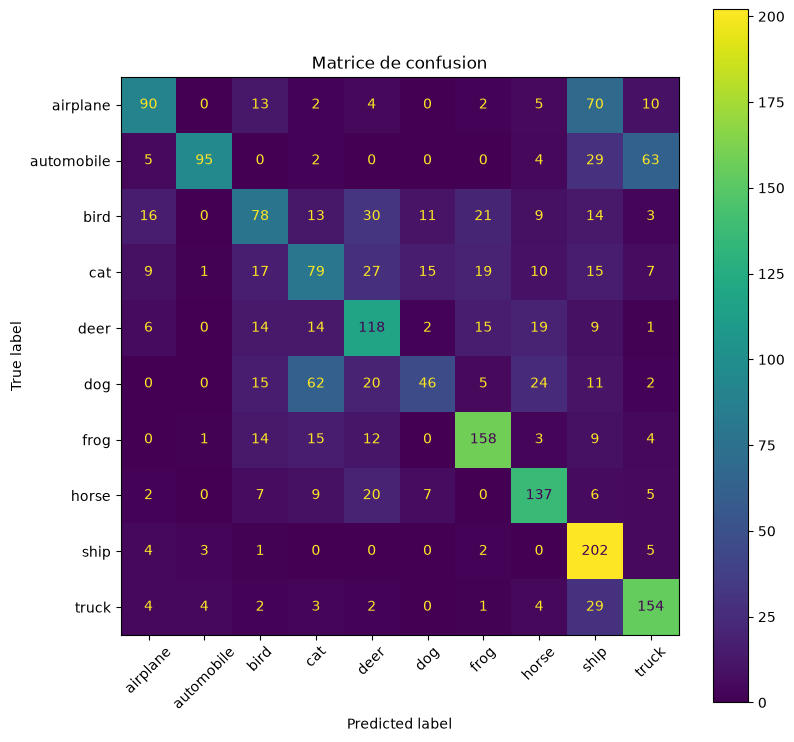

In [16]:
# matrice de confusion
CM_visualisation(cnn_model)

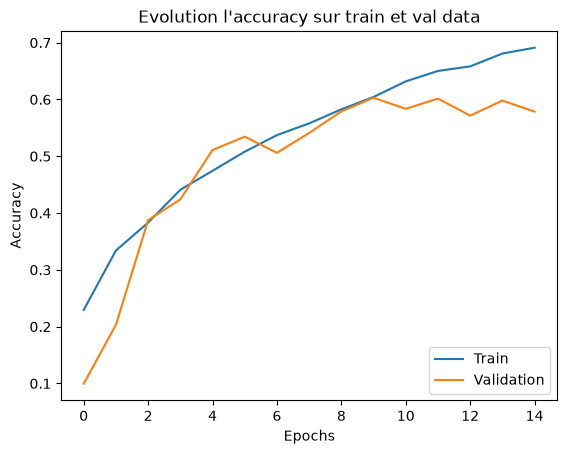

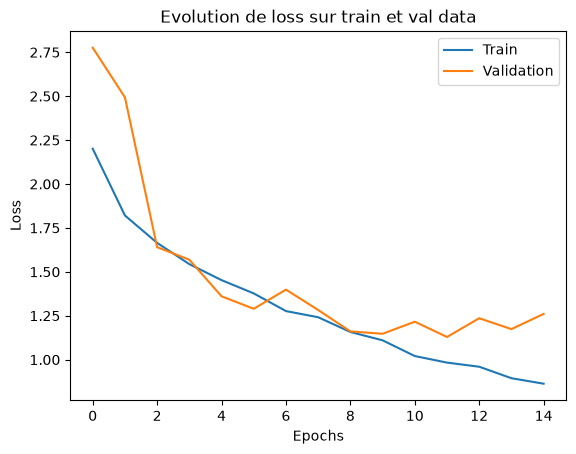

In [17]:
# Afficher les courbes d'accuracy et de loss
courbes(history_cnn)

In [18]:
# Accuracy et loss sur les données validation et sur train data
cnn_val = cnn_model.evaluate(test_images, test_labels, verbose = 0)
cnn_train = cnn_model.evaluate(train_images, train_labels, verbose = 0)
print(f"Validation -> Accuracy : {cnn_val[1]} ------ Loss : {cnn_val[0]}")
print(f"Train -> Accuracy : {cnn_train[1]} ------ Loss : {cnn_train[0]}")
resultats['CNN'] = {'Accuracy validation': cnn_val[1], 'Loss validation': cnn_val[0], 'Accuracy train': cnn_train[1], 'Loss train': cnn_train[0]}

Validation -> Accuracy : 0.578499972820282 ------ Loss : 1.2602468729019165
Train -> Accuracy : 0.7096999883651733 ------ Loss : 0.815661609172821


## Modèle 2 : VGG16

Base `imagenet` gelée, puis `Flatten`, deux couches `Dense` avec `Dropout`, et une sortie `softmax` à 10 classes. Hyperparamètres recherchés : neurones de Dense 1 (256, 512 ou 1024), de Dense 2 (128, 256 ou 512) et le taux de Dropout (0.3, 0.4 ou 0.5).

In [19]:
# fonction build_model de VGG16
def build_model_vgg16(hp):
  # Choisir les hyperparamètres
  hp_dense1 = hp.Choice('dense1', values = [256, 512, 1024])
  hp_dense2 = hp.Choice('dense2', values = [128, 256, 512])
  hp_dropout = hp.Choice('dropout', values = [0.3, 0.4, 0.5])

  # Charger VGG16 préentrainé sans les couches de classification (images 32x32 acceptées, minimum 32x32)
  base_vgg16 = VGG16(weights = 'imagenet', include_top = False, input_shape = (32, 32, 3))
  # Geler les couches de base (leurs poids restent fixes pendant l'entraînement)
  base_vgg16.trainable = False

  # Construire le modèle avec Sequential
  model = Sequential()
  model.add(base_vgg16) # ajouter les couches de convolutions de VGG16
  model.add(Flatten()) # Applanir
  model.add(Dense(units = hp_dense1, activation = 'relu')) # Dense 1
  model.add(Dropout(hp_dropout)) # Dropout 1
  model.add(Dense(units = hp_dense2, activation = 'relu')) # Dense 2
  model.add(Dropout(hp_dropout)) # Dropout 2
  model.add(Dense(units = 10, activation = 'softmax')) # Output : 10 classes

  # compiler le modèle
  model.compile(optimizer = 'adam', loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

  return model

In [20]:
# Initialiser le tuner de VGG16
tuner_vgg16 = kt.Hyperband(build_model_vgg16,
                     objective='val_accuracy',
                     max_epochs=MAX_EPOCHS_TUNER,
                     directory='tuner_dir',
                     project_name='vgg16_cifar10',
                     overwrite=True)

# lancer la recherche avec le tuner
tuner_vgg16.search(train_images, train_labels, validation_data = (test_images, test_labels), epochs = MAX_EPOCHS_TUNER, batch_size = 64)

Trial 10 Complete [00h 10m 47s]
val_accuracy: 0.5379999876022339

Best val_accuracy So Far: 0.546500027179718
Total elapsed time: 01h 19m 55s


In [21]:
# Afficher les paramètres optimaux de VGG16
best_hps_vgg16 = tuner_vgg16.get_best_hyperparameters()[0]
for h_param in ['dense1', 'dense2', 'dropout']:
  print(h_param, best_hps_vgg16.get(h_param))

dense1 1024
dense2 128
dropout 0.3


In [22]:
# Créer le modèle VGG16 final avec les hyperparamètres optimaux
vgg16_model = build_model_vgg16(best_hps_vgg16)
# summary
vgg16_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 1, 1, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,372,490 (58.64 MB)

 Trainable params: 657,802 (2.51 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [25]:
# Entraînement VGG16 (même early stopping que pour le CNN)
history_vgg16 = vgg16_model.fit(train_images, train_labels, validation_data = (test_images, test_labels), epochs = EPOCHS_FINAL, batch_size = 64, callbacks = early_stopping)
models['VGG16'] = vgg16_model

Epoch 1/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 112s 714ms/step - accuracy: 0.7529 - loss: 0.7021 - val_accuracy: 0.5795 - val_loss: 1.3565
Epoch 2/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 114s 727ms/step - accuracy: 0.7670 - loss: 0.6637 - val_accuracy: 0.5710 - val_loss: 1.4234
Epoch 3/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 112s 717ms/step - accuracy: 0.7741 - loss: 0.6369 - val_accuracy: 0.5785 - val_loss: 1.4236
Epoch 4/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 94s 595ms/step - accuracy: 0.7837 - loss: 0.6115 - val_accuracy: 0.5740 - val_loss: 1.4241


#### Evaluation

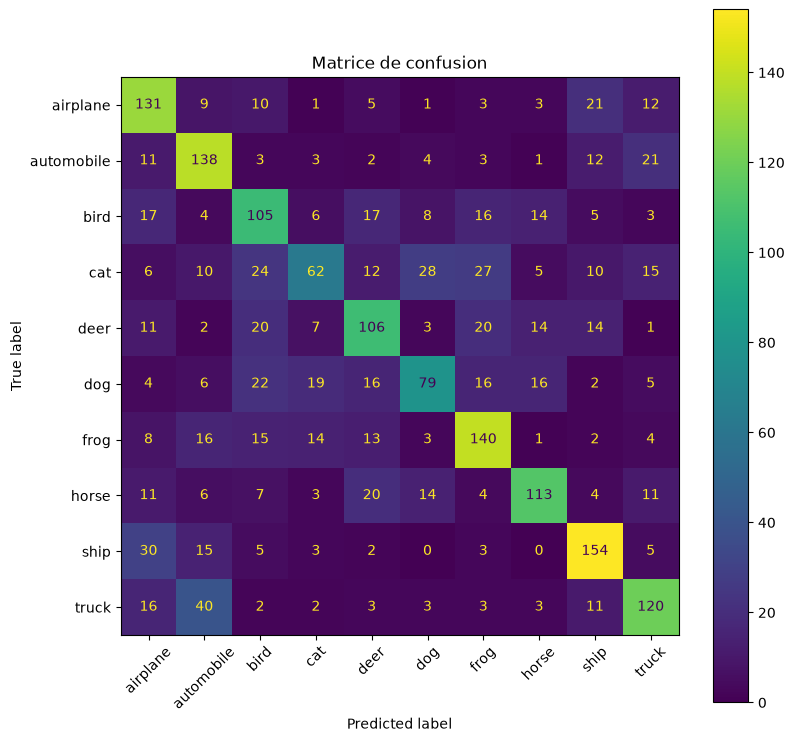

In [26]:
# matrice de confusion
CM_visualisation(vgg16_model)

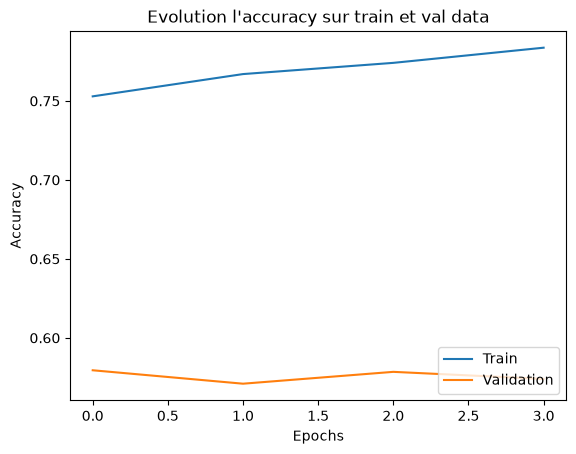

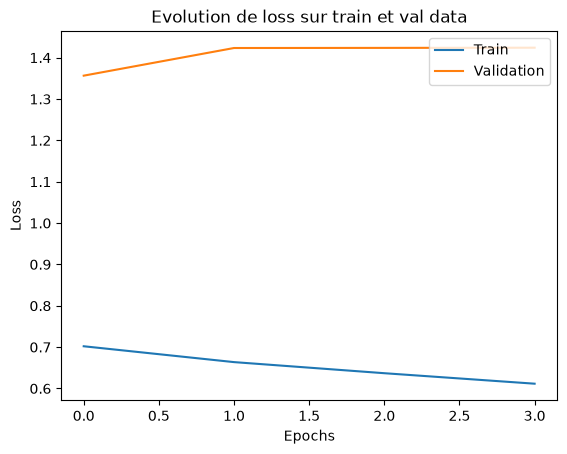

In [27]:
# Afficher les courbes d'accuracy et de loss
courbes(history_vgg16)

In [28]:
# Accuracy et loss sur les données validation et sur train data
vgg16_val = vgg16_model.evaluate(test_images, test_labels, verbose = 0)
vgg16_train = vgg16_model.evaluate(train_images, train_labels, verbose = 0)
print(f"Validation -> Accuracy : {vgg16_val[1]} ------ Loss : {vgg16_val[0]}")
print(f"Train -> Accuracy : {vgg16_train[1]} ------ Loss : {vgg16_train[0]}")
resultats['VGG16'] = {'Accuracy validation': vgg16_val[1], 'Loss validation': vgg16_val[0], 'Accuracy train': vgg16_train[1], 'Loss train': vgg16_train[0]}

Validation -> Accuracy : 0.5740000009536743 ------ Loss : 1.4241082668304443
Train -> Accuracy : 0.8507999777793884 ------ Loss : 0.44650498032569885


## Modèle 3 : DenseNet121

Même schéma que VGG16, avec la base `DenseNet121` (entrée 32×32 acceptée, minimum 32×32).

In [29]:
# fonction build_model de DenseNet121
def build_model_densenet121(hp):
  # Choisir les hyperparamètres
  hp_dense1 = hp.Choice('dense1', values = [256, 512, 1024])
  hp_dense2 = hp.Choice('dense2', values = [128, 256, 512])
  hp_dropout = hp.Choice('dropout', values = [0.3, 0.4, 0.5])

  # Charger DenseNet121 préentrainé sans les couches de classification
  base_densenet = DenseNet121(weights = 'imagenet', include_top = False, input_shape = (32, 32, 3))
  # Geler les couches de base
  base_densenet.trainable = False

  # Construire le modèle avec Sequential
  model = Sequential()
  model.add(base_densenet) # ajouter les couches de convolutions de DenseNet121
  model.add(Flatten()) # Applanir
  model.add(Dense(units = hp_dense1, activation = 'relu')) # Dense 1
  model.add(Dropout(hp_dropout)) # Dropout 1
  model.add(Dense(units = hp_dense2, activation = 'relu')) # Dense 2
  model.add(Dropout(hp_dropout)) # Dropout 2
  model.add(Dense(units = 10, activation = 'softmax')) # Output : 10 classes

  # compiler le modèle
  model.compile(optimizer = 'adam', loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

  return model

In [30]:
# Initialiser le tuner de DenseNet121
tuner_densenet = kt.Hyperband(build_model_densenet121,
                     objective='val_accuracy',
                     max_epochs=MAX_EPOCHS_TUNER,
                     directory='tuner_dir',
                     project_name='densenet121_cifar10',
                     overwrite=True)

# lancer la recherche avec le tuner
tuner_densenet.search(train_images, train_labels, validation_data = (test_images, test_labels), epochs = MAX_EPOCHS_TUNER, batch_size = 64)

Trial 10 Complete [00h 04m 50s]
val_accuracy: 0.5885000228881836

Best val_accuracy So Far: 0.6000000238418579
Total elapsed time: 00h 33m 29s


In [31]:
# Afficher les paramètres optimaux de DenseNet121
best_hps_densenet = tuner_densenet.get_best_hyperparameters()[0]
for h_param in ['dense1', 'dense2', 'dropout']:
  print(h_param, best_hps_densenet.get(h_param))

dense1 512
dense2 256
dropout 0.3


In [32]:
# Créer le modèle DenseNet121 final avec les hyperparamètres optimaux
densenet_model = build_model_densenet121(best_hps_densenet)
# summary
densenet_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 1, 1, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,696,202 (29.36 MB)

 Trainable params: 658,698 (2.51 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [34]:
# Entraînement DenseNet121 (même early stopping que pour le CNN)
history_densenet = densenet_model.fit(train_images, train_labels, validation_data = (test_images, test_labels), epochs = EPOCHS_FINAL, batch_size = 64, callbacks = early_stopping)
models['DenseNet121'] = densenet_model

Epoch 1/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 52s 328ms/step - accuracy: 0.7146 - loss: 0.7991 - val_accuracy: 0.6035 - val_loss: 1.1579
Epoch 2/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 84s 346ms/step - accuracy: 0.7431 - loss: 0.7229 - val_accuracy: 0.6155 - val_loss: 1.1913
Epoch 3/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 57s 361ms/step - accuracy: 0.7573 - loss: 0.6741 - val_accuracy: 0.6150 - val_loss: 1.2194
Epoch 4/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 56s 357ms/step - accuracy: 0.7761 - loss: 0.6261 - val_accuracy: 0.6055 - val_loss: 1.2576


#### Evaluation

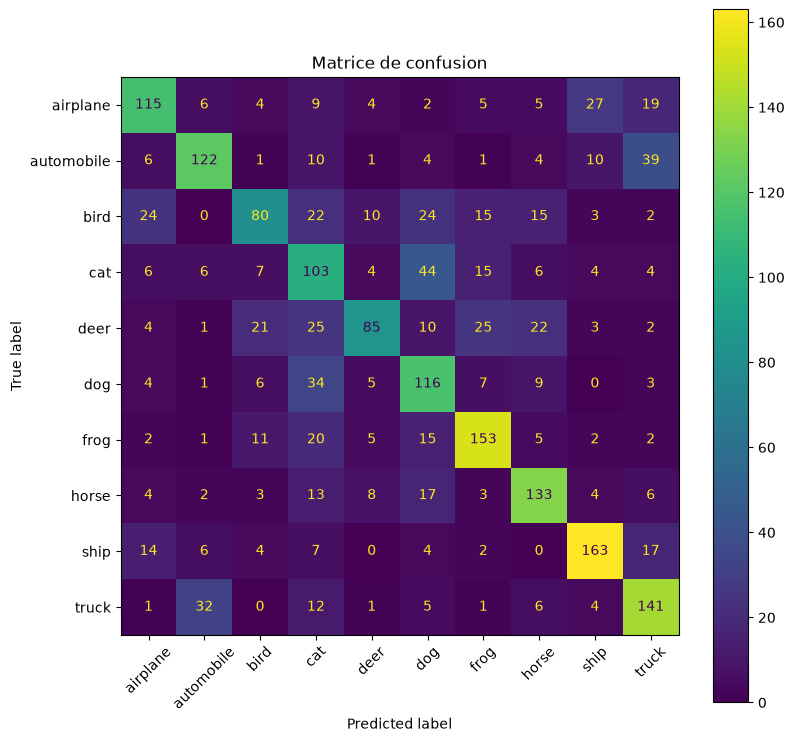

In [35]:
# matrice de confusion
CM_visualisation(densenet_model)

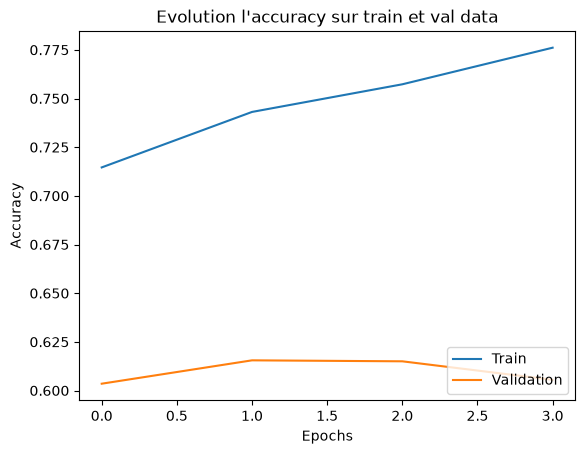

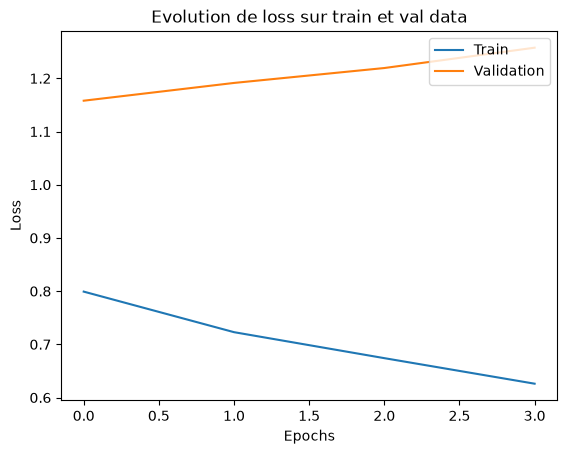

In [36]:
# Afficher les courbes d'accuracy et de loss
courbes(history_densenet)

In [37]:
# Accuracy et loss sur les données validation et sur train data
densenet_val = densenet_model.evaluate(test_images, test_labels, verbose = 0)
densenet_train = densenet_model.evaluate(train_images, train_labels, verbose = 0)
print(f"Validation -> Accuracy : {densenet_val[1]} ------ Loss : {densenet_val[0]}")
print(f"Train -> Accuracy : {densenet_train[1]} ------ Loss : {densenet_train[0]}")
resultats['DenseNet121'] = {'Accuracy validation': densenet_val[1], 'Loss validation': densenet_val[0], 'Accuracy train': densenet_train[1], 'Loss train': densenet_train[0]}

Validation -> Accuracy : 0.6054999828338623 ------ Loss : 1.2575706243515015
Train -> Accuracy : 0.8708999752998352 ------ Loss : 0.41636890172958374


## Comparaison des trois modèles

In [38]:
# Tableau comparatif des trois modèles (train et validation)
comparaison = pd.DataFrame(resultats).T
comparaison

,Accuracy validation,Loss validation,Accuracy train,Loss train
CNN,0.5785,1.260247,0.7097,0.815662
VGG16,0.5740,1.424108,0.8508,0.446505
DenseNet121,0.6055,1.257571,0.8709,0.416369


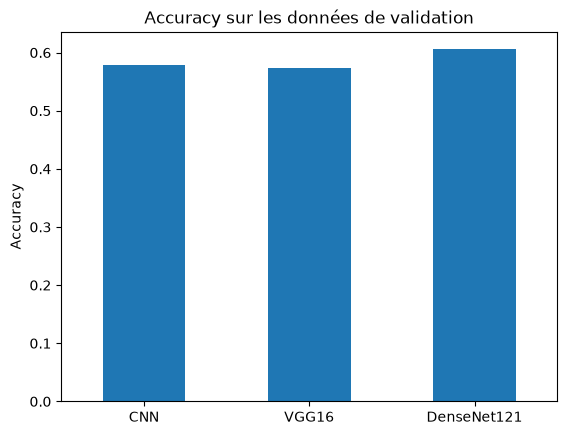

In [39]:
# Comparer l'accuracy sur les données de validation
comparaison['Accuracy validation'].plot(kind = 'bar')
plt.title('Accuracy sur les données de validation')
plt.ylabel('Accuracy')
plt.xticks(rotation = 0)
plt.show()

### Télécharger le modèle le plus performant

Le meilleur modèle est celui qui a la meilleure accuracy sur les données de validation.

In [40]:
# Choisir et sauvegarder le meilleur modèle
best_name = comparaison['Accuracy validation'].idxmax()
best_model = models[best_name]
print('Meilleur modèle :', best_name)
best_model.save('cifar10_best_model.h5')
best_model.save('cifar10_best_model.keras')

Meilleur modèle : DenseNet121


In [41]:
# Copier le meilleur modèle dans le dossier du projet (utilisé par l'application Streamlit)
import shutil
dossier = 'Projet/TP3'
os.makedirs(dossier, exist_ok = True)
shutil.copy('cifar10_best_model.h5', dossier)
shutil.copy('cifar10_best_model.keras', dossier)
os.listdir(dossier)

['cifar10_best_model.h5', 'cifar10_best_model.keras']

### Prédiction

In [42]:
# Fonction convertissant l'image à la dimension exacte utilisée sur le training
from PIL import Image

def imageToArray(image):

  width, height = 32, 32  #Remplacer par les dimensions requises par notre modèle

  image = image.convert('RGB') # convertir en 3 canaux (RGB)
  image = image.resize((width, height))
  # Convertir l'image en numpy array et normaliser les valeurs des pixels
  image_array = np.asarray(image)
  image_array = image_array / 255.0  # Normaliser les valeurs des pixels entre 0 et 1

  # Redimensionner la matrice image pour qu'elle correspond à la forme d'entrée de notre modèle
  image_array = image_array.reshape(1, width, height, 3)

  return image_array

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


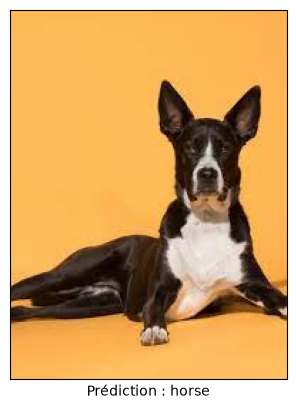

In [43]:
# Prédiction avec le meilleur modèle
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']
image_path = 'images/dog.jpg'
if os.path.exists(image_path):
  image = Image.open(image_path)
else:
  # si l'image n'existe pas dans le dossier 'images', on utilise la première image du jeu de test
  image = Image.fromarray((test_images[0] * 255).astype('uint8'))
  print("Image 'images/dog.jpg' introuvable : utilisation d'une image du jeu de test")
image_array = imageToArray(image) # redimensionne l'image
preds = best_model.predict(image_array) # prédiction
preds_single = class_names[np.argmax(preds)]
plt.xticks([])
plt.yticks([])
plt.imshow(image) # afficher l'image
plt.xlabel(f'Prédiction : {preds_single}')
plt.show()

### Préparation pour le déploiement avec Streamlit

La page Streamlit du TP3 affichera les probabilités des 10 classes. La fonction ci-dessous a le même prétraitement que l'entraînement (redimensionnement 32×32, division par 255) ; elle sera reprise dans `app.py`.

In [44]:
# Fonction de prédiction retournant la probabilité de chaque classe (même prétraitement que l'application Streamlit)
from tensorflow.keras.models import load_model
model = load_model('cifar10_best_model.h5')

def predict(image):
    image = image.convert('RGB')                      # gris/RGBA -> 3 canaux
    image = image.resize((32, 32))                    # Redimensionner à 32x32
    image_array = np.array(image) / 255.0             # Normaliser
    image_array = image_array.reshape(1, 32, 32, 3)   # Ajouter batch dimension
    predictions = model.predict(image_array, verbose = 0)[0] # probabilités de chaque classe
    return {class_names[i]: float(predictions[i]) for i in range(10)}

# Tester la fonction sur une image
predict(image)

{'airplane': 0.09918862581253052,
 'automobile': 2.0710900571430102e-05,
 'bird': 0.024104025214910507,
 'cat': 0.011833872646093369,
 'deer': 0.014050666242837906,
 'dog': 0.007344693411141634,
 'frog': 0.001857956638559699,
 'horse': 0.8375869989395142,
 'ship': 0.0005357888294383883,
 'truck': 0.003476589685305953}